# Bases de datos vectoriales

**Seminario de actualización · Unidad 6: Bases de datos No Relacionales (NoSQL) y Bases de Datos para IA**

Hasta ahora todas las búsquedas de texto del seminario se basaron en coincidencias literales: `LIKE`, los filtros de pandas o `$regex` en MongoDB. En esta clase vemos cómo representar el **significado** de un texto como un vector (embedding), cómo medir la similitud entre vectores, por qué hacen falta índices especiales para buscar entre millones de ellos y cómo se usa todo esto en **SQL Server 2025** con el tipo `VECTOR`.

**Cómo usar este notebook**

- Las secciones 1 a 4 se ejecutan solo con Python (numpy y pandas) y un modelo de embeddings local.
- La sección 5 contiene el T-SQL de SQL Server 2025. Se ejecuta si se activa la conexión en la celda de configuración; si no, muestra las sentencias para copiarlas a SSMS. Antes de esas celdas, cada ejemplo se reproduce en Python para poder comprobar los resultados.

## 0. Preparación del entorno

In [1]:
import importlib.util, subprocess, sys

PAQUETES = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib"}
faltan = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
print("Dependencias listas")
# Opcionales: pip install sentence-transformers (embeddings en Python) · pip install pyodbc (SQL Server)

Dependencias listas


### Configuración del modelo de embeddings

La función `embed()` convierte una lista de textos en una matriz de vectores normalizados. Foundry Local usa su servidor local (API compatible con OpenAI) y el cliente `openai`; el texto no se envía a un servicio externo. La primera vez descarga el modelo.

También puede usarse **Azure OpenAI** (`PROVEEDOR_EMBEDDINGS = "azure"`): requiere las variables `AZURE_OPENAI_ENDPOINT`, `AZURE_OPENAI_API_KEY` y `AZURE_OPENAI_DEPLOYMENT` (nombre del *deployment* de embeddings) en `.env`. En ese caso **los textos sí se envían a un servicio en la nube** y se factura por token.

Como alternativas, puede usarse `sentence-transformers` con `paraphrase-multilingual-MiniLM-L12-v2` (384 dimensiones), o el modo `simple`, que solo compara fragmentos de letras y **no captura significado**.

La celda siguiente instala el cliente `openai` si hace falta. También se necesita tener Foundry Local instalado en el equipo y el comando `foundry` disponible en `PATH`; el notebook inicia el servidor (`foundry server start`) y carga el modelo con la CLI. Cambiar `PROVEEDOR_EMBEDDINGS` a `"azure"`, `"foundry"`, `"sentence-transformers"` o `"simple"` para forzar un proveedor. Ejecutar `listar_modelos_foundry()` para consultar los modelos disponibles.

In [2]:
import importlib.util, os, re, subprocess, sys, zlib, unicodedata
import shutil
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd

import json

INSTALAR_FOUNDRY = True           # instala el cliente openai si falta
if INSTALAR_FOUNDRY and importlib.util.find_spec("openai") is None:
    print(f"Instalando openai en {sys.executable}")
    resultado = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "openai"],
        capture_output=True, text=True)
    importlib.invalidate_caches()
    if resultado.returncode != 0:
        detalle = (resultado.stderr or resultado.stdout).strip()
        print(f"No se pudo instalar openai ({sys.version.split()[0]}, {sys.platform}).")
        print(detalle[-1200:] or "pip terminó con error sin devolver detalles.")
        print("Se probará el proveedor alternativo.")
    elif importlib.util.find_spec("openai") is None:
        print("openai se instaló, pero este kernel no lo encuentra. Reinicie el kernel.")

PROVEEDOR_EMBEDDINGS = "azure"     # "auto" | "azure" | "foundry" | "sentence-transformers" | "simple"
AZURE_API_VERSION = "2024-10-21"
_cliente_azure = None
MODELO_FOUNDRY_EMB = "qwen3-embedding-0.6b"
MODELO_ST = "paraphrase-multilingual-MiniLM-L12-v2"
# Se actualiza con la dirección que informa el servidor local al iniciarse.
FOUNDRY_URL = None

_modelos_foundry = {}
_cliente_foundry = None


def _cli_foundry(*args, timeout=900):
    """Ejecuta el comando `foundry` y devuelve (código de salida, salida de texto)."""
    r = subprocess.run(["foundry", *args], capture_output=True, text=True,
                       encoding="utf-8", errors="replace", timeout=timeout)
    return r.returncode, (r.stdout or "") + (r.stderr or "")


def _estado_servidor():
    codigo, salida = _cli_foundry("server", "status", "-o", "json", timeout=60)
    try:
        estado = json.loads(salida[salida.index("{"):salida.rindex("}") + 1])
    except ValueError:
        return None
    return estado["webUrls"][0] if estado.get("running") and estado.get("webUrls") else None


def foundry():
    """Inicia el servidor de Foundry Local si hace falta y devuelve su URL base."""
    global FOUNDRY_URL
    url = _estado_servidor()
    if url is None:
        print("Iniciando el servidor de Foundry Local (puede demorar)...")
        codigo, salida = _cli_foundry("server", "start", timeout=600)
        url = _estado_servidor()
        if url is None:
            raise RuntimeError(f"No se pudo iniciar el servidor de Foundry Local: {salida.strip()[-300:]}")
    FOUNDRY_URL = url
    return url


def listar_modelos_foundry():
    """Muestra el catálogo de modelos de Foundry Local."""
    print(_cli_foundry("model", "list")[1])


def modelo_foundry(alias):
    """Descarga (si hace falta) y carga en memoria un modelo; devuelve su id."""
    if alias not in _modelos_foundry:
        foundry()
        print(f"Preparando {alias} (la primera vez se descarga)...")
        codigo, salida = _cli_foundry("model", "download", alias)
        if codigo != 0:
            raise ValueError(f"No se pudo descargar '{alias}'. Ver listar_modelos_foundry(). {salida.strip()[-300:]}")
        codigo, salida = _cli_foundry("model", "load", alias)
        if codigo != 0:
            raise RuntimeError(f"No se pudo cargar '{alias}': {salida.strip()[-300:]}")
        m = re.search(r"variant '([^']+)'", salida)
        if m is None:
            m = re.search(rf"'({re.escape(alias)}[^']*:\d+)'", salida)
        if m is None:
            raise RuntimeError(f"No se pudo determinar el id del modelo cargado: {salida.strip()[-300:]}")
        _modelos_foundry[alias] = m.group(1)
    return _modelos_foundry[alias]


def _foundry_funciona():
    if importlib.util.find_spec("openai") is None:
        return False
    if shutil.which("foundry") is None:
        print("No se encontró el comando 'foundry' en PATH; instale Foundry Local para usar este proveedor.")
        return False
    return True


def _azure_funciona():
    variables = ("AZURE_OPENAI_ENDPOINT", "AZURE_OPENAI_API_KEY", "AZURE_OPENAI_DEPLOYMENT")
    return importlib.util.find_spec("openai") is not None and all(os.getenv(v) for v in variables)


def _elegir_proveedor():
    if PROVEEDOR_EMBEDDINGS != "auto":
        return PROVEEDOR_EMBEDDINGS
    if _azure_funciona():
        return "azure"
    if _foundry_funciona():
        return "foundry"
    if importlib.util.find_spec("sentence_transformers") is not None:
        return "sentence-transformers"
    return "simple"


def _sin_acentos(texto):
    texto = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in texto if unicodedata.category(c) != "Mn")


def _embedding_simple(texto, dim=512):
    """Respaldo sin modelo: cuenta trigramas de letras en un vector de tamaño fijo (hashing)."""
    v = np.zeros(dim, dtype=np.float32)
    for palabra in re.findall(r"\w+", _sin_acentos(texto)):
        p = f" {palabra} "
        for i in range(len(p) - 2):
            v[zlib.crc32(p[i:i + 3].encode()) % dim] += 1
    return v


_modelo_st = None


def embed(textos, lote=32):
    """Devuelve una matriz (cantidad de textos x dimensiones) con vectores de longitud 1."""
    global PROVEEDOR_ACTIVO, _modelo_st, _cliente_azure
    if isinstance(textos, str):
        textos = [textos]
    textos = list(textos)
    if PROVEEDOR_ACTIVO == "azure":
        try:
            from openai import AzureOpenAI
            if _cliente_azure is None:
                _cliente_azure = AzureOpenAI(
                    azure_endpoint=os.environ["AZURE_OPENAI_ENDPOINT"],
                    api_key=os.environ["AZURE_OPENAI_API_KEY"],
                    api_version=AZURE_API_VERSION)
            filas = []
            for i in range(0, len(textos), lote):
                respuesta = _cliente_azure.embeddings.create(
                    input=textos[i:i + lote], model=os.environ["AZURE_OPENAI_DEPLOYMENT"])
                filas.extend(d.embedding for d in sorted(respuesta.data, key=lambda d: d.index))
            M = np.array(filas, dtype=np.float32)
        except Exception as e:
            siguiente = "foundry" if _foundry_funciona() else (
                "sentence-transformers" if importlib.util.find_spec("sentence_transformers") else "simple")
            print(f"No se pudo usar Azure OpenAI ({type(e).__name__}: {str(e)[:150]}). Se usa {siguiente}.")
            PROVEEDOR_ACTIVO = siguiente
            return embed(textos)
    elif PROVEEDOR_ACTIVO == "foundry":
        try:
            from openai import OpenAI
            modelo = modelo_foundry(MODELO_FOUNDRY_EMB)
            global _cliente_foundry
            if _cliente_foundry is None:
                _cliente_foundry = OpenAI(base_url=f"{foundry()}/v1", api_key="no-necesita")
            filas = []
            for i in range(0, len(textos), lote):
                respuesta = _cliente_foundry.embeddings.create(
                    input=textos[i:i + lote], model=modelo)
                filas.extend(d.embedding for d in sorted(respuesta.data, key=lambda d: d.index))
            M = np.array(filas, dtype=np.float32)
        except Exception as e:
            siguiente = "sentence-transformers" if importlib.util.find_spec("sentence_transformers") else "simple"
            print(f"No se pudo usar Foundry Local ({type(e).__name__}: {str(e)[:150]}). Se usa {siguiente}.")
            PROVEEDOR_ACTIVO = siguiente
            return embed(textos)
    elif PROVEEDOR_ACTIVO == "sentence-transformers":
        try:
            if _modelo_st is None:
                from sentence_transformers import SentenceTransformer
                _modelo_st = SentenceTransformer(MODELO_ST)
            M = _modelo_st.encode(textos, convert_to_numpy=True)
        except Exception as e:
            print(f"No se pudo cargar {MODELO_ST} ({type(e).__name__}). Se usa el modo simple.")
            PROVEEDOR_ACTIVO = "simple"
            return embed(textos)
    else:
        M = np.array([_embedding_simple(t) for t in textos])
    return M / np.clip(np.linalg.norm(M, axis=1, keepdims=True), 1e-12, None)


PROVEEDOR_ACTIVO = _elegir_proveedor()
DIM = embed(["prueba"]).shape[1]
print(f"Proveedor de embeddings: {PROVEEDOR_ACTIVO} · dimensiones: {DIM}")
if PROVEEDOR_ACTIVO == "simple":
    print("Atención: modo de respaldo sin significado. Usar Foundry Local o sentence-transformers para resultados reales.")

Proveedor de embeddings: azure · dimensiones: 1536


### Configuración de SQL Server 2025

Las celdas de T-SQL se ejecutan con **pyodbc** contra la instancia del laboratorio. Para activarlas:

1. Poner `USAR_SQLSERVER = True`.
2. Ajustar `CADENA_CONEXION` (servidor, base y autenticación). La base debe existir.
3. Tener instalado el *ODBC Driver 18 for SQL Server* y el paquete `pyodbc` (`pip install pyodbc`).

Con `USAR_SQLSERVER = False`, la función `sql()` muestra el T-SQL que se ejecutaría, sin conectarse. Así se puede leer el notebook completo en cualquier equipo y copiar las sentencias a SSMS o a Visual Studio Code.

In [3]:
USAR_SQLSERVER = True
# Usar la información de conexión de .env
Server = os.getenv("Server", "localhost")
Database = os.getenv("Database", "Seminario")
User = os.getenv("User", "")
Password = os.getenv("Password", "")
CADENA_CONEXION = (
    "DRIVER={ODBC Driver 18 for SQL Server};"
    f"SERVER={Server};DATABASE={Database};"
    f"UID={User};PWD={Password};"
    "Encrypt=yes;TrustServerCertificate=yes;"
)

conn = None
if USAR_SQLSERVER:
    import pyodbc
    conn = pyodbc.connect(CADENA_CONEXION, autocommit=True)
    print(conn.execute("SELECT @@VERSION").fetchone()[0].splitlines()[0])
else:
    print("SQL Server desactivado: las celdas T-SQL se muestran pero no se ejecutan.")


def sql(consulta, *parametros):
    """Ejecuta un lote T-SQL con parámetros (?) y devuelve el primer resultado como DataFrame."""
    if conn is None:
        print("-- T-SQL (sin conexión, no se ejecutó):\n" + consulta.strip() + "\n")
        return None
    cur = conn.cursor()
    if parametros:
        # Los textos largos (vectores en JSON) deben viajar como nvarchar(max), no como ntext.
        cur.setinputsizes([(pyodbc.SQL_WVARCHAR, 0, 0) if isinstance(p, str) and len(p) > 2000 else None
                           for p in parametros])
    cur.execute(consulta, parametros) if parametros else cur.execute(consulta)
    while True:
        if cur.description:
            columnas = [c[0] for c in cur.description]
            return pd.DataFrame.from_records(cur.fetchall(), columns=columnas)
        if not cur.nextset():
            return None

Microsoft SQL Server 2025 (RTM-CU9) (KB5122048) - 17.0.5005.3 (X64) 


## 1. LIKE encuentra palabras; los vectores encuentran ideas

La frase "el estudiante pasó el examen" no contiene la palabra "aprobó", pero significa lo mismo que "el alumno aprobó el parcial". Una búsqueda literal no puede verlo:

In [4]:
comentarios = ["el alumno aprobó el parcial", "el estudiante pasó el examen", "receta de empanadas salteñas"]

# Equivalente a: SELECT Texto FROM dbo.Comentarios WHERE Texto LIKE '%aprobó%'
[c for c in comentarios if "aprobó" in c]

['el alumno aprobó el parcial']

## 2. Embeddings

> **Definición clave.** Un **embedding** es un vector de números reales que representa el significado de un contenido (texto, imagen, audio), de modo que contenidos parecidos quedan ubicados cerca en el espacio vectorial. Lo genera un **modelo de embeddings**, una red neuronal entrenada con grandes volúmenes de datos.

Cada modelo produce vectores de una dimensión fija (de 384 a 3072 valores). Ninguna dimensión tiene un significado legible por sí sola: lo que importa es la posición relativa de los vectores.

| Modelo | Dimensiones | Dónde se ejecuta |
|---|---|---|
| text-embedding-3-small (OpenAI) | 1536 | Servicio en la nube |
| qwen3-embedding-0.6b | 1024 | Local, con Foundry Local |
| nomic-embed-text | 768 | Local, con Ollama |
| all-MiniLM-L6-v2 / paraphrase-multilingual-MiniLM-L12-v2 | 384 | Local, con sentence-transformers |

In [5]:
vectores = embed(comentarios)
print("Forma de la matriz:", vectores.shape, "(frases x dimensiones)\n")
for frase, v in zip(comentarios, vectores):
    print(f"{frase!r:35} -> [{', '.join(f'{x:.3f}' for x in v[:4])}, ...]")

Forma de la matriz: (3, 1536) (frases x dimensiones)

'el alumno aprobó el parcial'       -> [0.006, -0.001, 0.003, -0.035, ...]
'el estudiante pasó el examen'      -> [0.025, -0.027, 0.000, -0.054, ...]
'receta de empanadas salteñas'      -> [0.034, -0.053, 0.011, -0.020, ...]


> **Regla de oro.** Un vector generado con un modelo no es comparable con uno generado con otro, aunque tengan la misma dimensión. Documentos y consultas se vectorizan siempre con el **mismo modelo**; si se cambia de modelo, hay que regenerar todos los embeddings.

## 3. Medidas de similitud

| Medida | Fórmula | Mejor resultado | Cuándo se usa |
|---|---|---|---|
| Similitud coseno | $\cos\theta = \dfrac{a \cdot b}{\lVert a\rVert \, \lVert b\rVert}$ | Cercana a 1 (distancia coseno $= 1-\cos\theta$ cercana a 0) | Texto; la opción por defecto. |
| Distancia euclidiana | $d = \sqrt{\sum (a_i - b_i)^2}$ | Cercana a 0 | Cuando la magnitud del vector tiene significado. |
| Producto punto | $a \cdot b = \sum a_i b_i$ | Valor más alto | Vectores normalizados; recomendaciones. |

Las implementamos "a mano" con numpy para ver que no hay magia:

In [6]:
def producto_punto(a, b):
    return float(np.sum(np.asarray(a) * np.asarray(b)))


def norma(a):
    return float(np.sqrt(producto_punto(a, a)))


def similitud_coseno(a, b):
    return producto_punto(a, b) / (norma(a) * norma(b))


def distancia_euclidiana(a, b):
    return float(np.sqrt(np.sum((np.asarray(a) - np.asarray(b)) ** 2)))


# Ejemplo del apunte: a = (3, 4), b = (4, 3)
a, b = (3, 4), (4, 3)
print("a · b             =", producto_punto(a, b))
print("‖a‖ = ‖b‖         =", norma(a))
print("similitud coseno  =", round(similitud_coseno(a, b), 2))
print("distancia coseno  =", round(1 - similitud_coseno(a, b), 2))
print("distancia euclid. =", round(distancia_euclidiana(a, b), 3))

a · b             = 24.0
‖a‖ = ‖b‖         = 5.0
similitud coseno  = 0.96
distancia coseno  = 0.04
distancia euclid. = 1.414


**Ejercicio:** calcular a mano la similitud coseno entre (1, 0) y (1, 1) y verificar con la celda siguiente.

In [7]:
# Verificación: (1·1 + 0·1) / (1 · √2) = 1/√2
round(similitud_coseno((1, 0), (1, 1)), 4)

0.7071

Con vectores **normalizados** (longitud 1) el denominador del coseno vale 1, así que el producto punto **es** la similitud coseno, y es más barato de calcular. Por eso `embed()` devuelve vectores normalizados y la matriz de similitudes se obtiene con una sola multiplicación `V @ V.T`:

In [8]:
frases = [
    "el alumno aprobó el parcial",
    "el estudiante pasó el examen",
    "la profesora tomó una evaluación difícil",
    "receta de empanadas salteñas",
    "cómo preparar un locro para el 25 de mayo",
    "el horno tiene que estar bien caliente",
    "el servidor de base de datos se cayó",
    "la consulta SQL tarda demasiado",
    "hay que crear un índice en la tabla",
    "mañana llueve en Buenos Aires",
]
V = embed(frases)
similitudes = pd.DataFrame(V @ V.T, index=frases, columns=range(len(frases))).round(2)
similitudes.style.background_gradient(cmap="Blues", axis=None).format("{:.2f}")

,0,1,2,3,4,5,6,7,8,9
el alumno aprobó el parcial,1.00,0.75,0.54,0.20,0.21,0.25,0.24,0.20,0.19,0.26
el estudiante pasó el examen,0.75,1.00,0.55,0.19,0.22,0.26,0.29,0.23,0.21,0.25
la profesora tomó una evaluación difícil,0.54,0.55,1.00,0.19,0.21,0.25,0.23,0.30,0.20,0.22
receta de empanadas salteñas,0.20,0.19,0.19,1.00,0.38,0.30,0.18,0.15,0.17,0.22
cómo preparar un locro para el 25 de mayo,0.21,0.22,0.21,0.38,1.00,0.37,0.18,0.18,0.20,0.32
el horno tiene que estar bien caliente,0.25,0.26,0.25,0.30,0.37,1.00,0.20,0.23,0.31,0.21
el servidor de base de datos se cayó,0.24,0.29,0.23,0.18,0.18,0.20,1.00,0.38,0.33,0.26
la consulta SQL tarda demasiado,0.20,0.23,0.30,0.15,0.18,0.23,0.38,1.00,0.42,0.20
hay que crear un índice en la tabla,0.19,0.21,0.20,0.17,0.20,0.31,0.33,0.42,1.00,0.20
mañana llueve en Buenos Aires,0.26,0.25,0.22,0.22,0.32,0.21,0.26,0.20,0.20,1.00


Con un modelo de embeddings real, los bloques de frases del mismo tema (examen, cocina, bases de datos) deberían tener similitudes más altas entre sí que con el resto. Para verlo de otra forma, proyectamos los vectores a dos dimensiones con análisis de componentes principales (PCA): frases parecidas deberían quedar cerca en el gráfico.

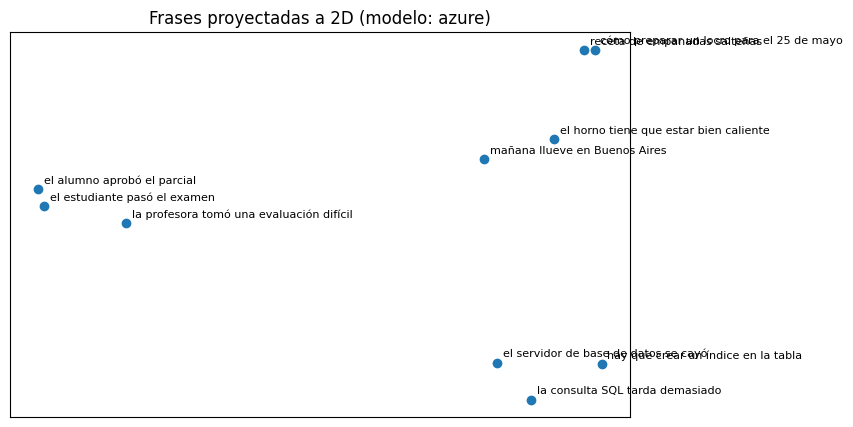

In [9]:
import matplotlib.pyplot as plt

centrados = V - V.mean(axis=0)
_, _, componentes = np.linalg.svd(centrados, full_matrices=False)
xy = centrados @ componentes[:2].T

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(xy[:, 0], xy[:, 1])
for (x, y), frase in zip(xy, frases):
    ax.annotate(frase, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_title(f"Frases proyectadas a 2D (modelo: {PROVEEDOR_ACTIVO})")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 4. Búsqueda semántica

La búsqueda semántica sigue siempre cuatro pasos:

1. Se generan los embeddings de todos los documentos y se guardan junto al texto original.
2. Cuando llega una consulta, se genera su embedding **con el mismo modelo**.
3. Se buscan los *k* vectores más cercanos al de la consulta (*k-nearest neighbors*, kNN).
4. Se devuelven los documentos asociados, ordenados por similitud.

In [10]:
documentos = pd.DataFrame({"Texto": frases})
documentos["Embedding"] = list(V)          # paso 1: texto + vector


def buscar(consulta, k=3):
    q = embed(consulta)[0]                                   # paso 2
    sim = np.vstack(documentos["Embedding"]) @ q             # similitud coseno (vectores normalizados)
    mejores = np.argsort(-sim)[:k]                           # paso 3: los k más parecidos
    return documentos.iloc[mejores][["Texto"]].assign(Similitud=sim[mejores].round(3))   # paso 4


buscar("me fue bien en la prueba")

,Texto,Similitud
1,el estudiante pasó el examen,0.595
0,el alumno aprobó el parcial,0.582
2,la profesora tomó una evaluación difícil,0.489


In [11]:
buscar("problemas de rendimiento en la base")

,Texto,Similitud
6,el servidor de base de datos se cayó,0.552
7,la consulta SQL tarda demasiado,0.445
8,hay que crear un índice en la tabla,0.359


### Palabras clave frente a semántica

| Característica | Palabras clave (LIKE, full-text) | Semántica (vectores) |
|---|---|---|
| Encuentra | Coincidencias literales | Coincidencias de significado |
| Sinónimos y paráfrasis | No | Sí |
| Códigos, legajos, siglas | Muy bien | Mal |
| Explicabilidad del resultado | Alta | Baja |

**Ejercicio:** buscar un ejemplo donde la búsqueda por palabras clave funcione mejor. Una pista: códigos exactos.

In [12]:
tickets = ["Error al cargar notas del legajo 1024", "Error al cargar notas del legajo 1042",
           "El legajo 2048 no puede inscribirse", "Consulta sobre la materia BD2", "Consulta sobre la materia BD1"]
T = embed(tickets)
consulta = "legajo 1042"

print("Palabras clave:", [t for t in tickets if "1042" in t])
sim = T @ embed(consulta)[0]
print("Semántica (ranking):")
for i in np.argsort(-sim):
    print(f"  {sim[i]:.3f}  {tickets[i]}")

Palabras clave: ['Error al cargar notas del legajo 1042']
Semántica (ranking):
  0.540  Error al cargar notas del legajo 1042
  0.531  El legajo 2048 no puede inscribirse
  0.474  Error al cargar notas del legajo 1024
  0.299  Consulta sobre la materia BD1
  0.289  Consulta sobre la materia BD2


Para un modelo de embeddings, "legajo 1024" y "legajo 1042" son casi lo mismo: el número no tiene "significado". Por eso los sistemas reales usan **búsqueda híbrida**: ejecutan las dos búsquedas y combinan los rankings (lo implementamos en la clase 30).

## 5. Bases de datos vectoriales

### 5.1 Por qué no alcanza con un índice tradicional

Un índice B-tree ordena valores en **una** dimensión: sirve para encontrar un legajo o un rango de fechas, pero no el punto más cercano en un espacio de 768 dimensiones. La búsqueda exacta (kNN) compara la consulta con **todos** los vectores: es precisa, pero su costo crece en forma lineal con la cantidad de filas. Lo medimos:

In [13]:
import time

rng = np.random.default_rng(0)
consulta_aleatoria = rng.normal(size=128).astype(np.float32)
filas = []
for n in (10_000, 50_000, 100_000, 200_000):
    X = rng.normal(size=(n, 128)).astype(np.float32)
    inicio = time.perf_counter()
    for _ in range(20):
        np.argsort(-(X @ consulta_aleatoria))[:10]
    filas.append({"vectores": n, "ms por consulta": round((time.perf_counter() - inicio) / 20 * 1000, 2)})
pd.DataFrame(filas)

,vectores,ms por consulta
0,10000,0.74
1,50000,2.13
2,100000,5.16
3,200000,10.27


### 5.2 Búsqueda aproximada (ANN) y recall

Los índices **ANN** (*Approximate Nearest Neighbors*) recorren solo una parte del espacio: pierden algo de precisión a cambio de responder en milisegundos. La calidad se mide con el **recall**: qué proporción de los vecinos verdaderos devuelve el índice.

| Índice | Idea | Ventaja | Costo |
|---|---|---|---|
| HNSW | Grafo de varias capas; va de lo general a lo particular. | Muy rápido, alto recall. | Mucha RAM. |
| IVF (Inverted File) | Agrupa los vectores en clusters y busca solo en los más cercanos. | Simple y económico. | El recall depende de cuántos clusters se revisan. |
| DiskANN | Grafo optimizado para disco SSD (el que usa SQL Server 2025). | Miles de millones de vectores con poca RAM. | Algo más lento que HNSW. |
| PQ | Comprime cada vector en códigos cortos. | Menos almacenamiento. | Pierde precisión. |

Implementamos un índice **IVF** mínimo para ver el compromiso entre velocidad y recall:

1. Se agrupan los vectores en clusters con k-means; cada cluster tiene un centroide.
2. Para una consulta se eligen los `nprobe` centroides más cercanos y solo se comparan los vectores de esos clusters.

In [14]:
# Datos de prueba: 40.000 vectores de 64 dimensiones agrupados en 40 "temas"
temas = rng.normal(size=(40, 64))
X = (temas[rng.integers(0, 40, 40_000)] + 0.35 * rng.normal(size=(40_000, 64))).astype(np.float32)
X /= np.linalg.norm(X, axis=1, keepdims=True)
consultas = X[rng.choice(len(X), 100, replace=False)] + 0.05 * rng.normal(size=(100, 64)).astype(np.float32)

# 1. k-means simple para construir el índice (40 clusters)
centroides = X[rng.choice(len(X), 40, replace=False)].copy()
for _ in range(10):
    asignacion = np.argmax(X @ centroides.T, axis=1)
    for c in range(len(centroides)):
        miembros = X[asignacion == c]
        if len(miembros):
            centroides[c] = miembros.mean(axis=0) / np.linalg.norm(miembros.mean(axis=0))
listas = {c: np.where(asignacion == c)[0] for c in range(len(centroides))}


def knn_exacto(q, k=10):
    return np.argsort(-(X @ q))[:k], len(X)


def knn_ivf(q, k=10, nprobe=1):
    cercanos = np.argsort(-(centroides @ q))[:nprobe]                  # 2. clusters más cercanos
    candidatos = np.concatenate([listas[c] for c in cercanos])
    orden = np.argsort(-(X[candidatos] @ q))[:k]
    return candidatos[orden], len(candidatos)


def evaluar(funcion, **kw):
    recalls, comparados, inicio = [], [], time.perf_counter()
    for q in consultas:
        verdaderos, _ = knn_exacto(q)
        encontrados, n = funcion(q, **kw)
        recalls.append(len(set(verdaderos) & set(encontrados)) / len(verdaderos))
        comparados.append(n)
    return {"recall@10": round(np.mean(recalls), 3), "vectores comparados": int(np.mean(comparados)),
            "ms por consulta": round((time.perf_counter() - inicio) / len(consultas) * 1000, 2)}


resultados = [{"método": "kNN exacto", **evaluar(knn_exacto)}]
for nprobe in (1, 2, 4, 8):
    resultados.append({"método": f"IVF nprobe={nprobe}", **evaluar(knn_ivf, nprobe=nprobe)})
pd.DataFrame(resultados)

,método,recall@10,vectores comparados,ms por consulta
0,kNN exacto,1.000,40000,4.82
1,IVF nprobe=1,0.976,1410,1.47
2,IVF nprobe=2,1.000,2127,1.71
3,IVF nprobe=4,1.000,4177,3.01
4,IVF nprobe=8,1.000,8217,3.04


*(El tiempo del IVF incluye también la búsqueda exacta usada para medir el recall; la columna que muestra el ahorro real es "vectores comparados".)*

Revisando 1 de 40 clusters se compara una fracción mínima de los vectores; al aumentar `nprobe` el recall sube y el costo también. Como regla práctica: con pocos miles de filas alcanza la búsqueda exacta; con cientos de miles o millones hace falta un índice ANN.

### 5.3 Panorama de soluciones (Joshi, 2025)

| Familia | Ejemplos | Característica |
|---|---|---|
| Bases vectoriales especializadas | Pinecone, Qdrant, Milvus | Máximo rendimiento a gran escala; un sistema más para administrar. |
| Servicios en la nube | Vertex AI Vector Search, Azure Cosmos DB, Amazon Aurora | Administrados e integrados con servicios de IA. |
| Soporte vectorial en plataformas existentes | pgvector, AlloyDB AI, Databricks, Snowflake Cortex, **SQL Server 2025** | Los vectores conviven con los datos relacionales. |
| Frameworks de integración | LangChain, Semantic Kernel, Spring AI | Conectan bases vectoriales con LLM. |

En el seminario usamos la tercera opción: evita copiar los datos a otro sistema y permite combinar filtros SQL, permisos y búsqueda semántica en una sola consulta.

## 6. Vectores en SQL Server 2025

| Función o instrucción | Qué hace |
|---|---|
| `VECTOR(n)` | Tipo de dato de *n* dimensiones; se carga desde un arreglo JSON en texto. |
| `VECTOR_DISTANCE(métrica, v1, v2)` | Distancia exacta: `'cosine'`, `'euclidean'` o `'dot'`. |
| `VECTOR_NORM` / `VECTOR_NORMALIZE` | Longitud del vector / vector de longitud 1. |
| `CREATE VECTOR INDEX` | Índice ANN basado en DiskANN. |
| `VECTOR_SEARCH(...)` | Búsqueda aproximada usando el índice. |
| `CREATE EXTERNAL MODEL` | Registra un modelo de embeddings (Azure OpenAI, OpenAI, Ollama). Foundry Local se registra con el formato OpenAI. |
| `AI_GENERATE_EMBEDDINGS` | Genera el embedding de un texto desde T-SQL. |

Algunas funciones (índice vectorial, `VECTOR_SEARCH`, generación de embeddings) pueden requerir habilitar las características en vista previa, según la versión instalada. Como son funciones nuevas, su sintaxis puede variar entre versiones: ante un error de sintaxis, verificar la página de cada función en Microsoft Learn.

### 6.1 El ejemplo de las películas, primero en Python

Vectores de tres dimensiones que representan cuánto tiene cada película de **[acción, romance, humor]**. Así se puede seguir el cálculo sin un modelo de embeddings. Reproducimos en numpy lo que hace `VECTOR_DISTANCE`:

In [16]:
peliculas = pd.DataFrame([
    ("Duro de matar", "Acción", [0.95, 0.05, 0.20]),
    ("Rocky", "Acción", [0.80, 0.30, 0.10]),
    ("Diario de una pasión", "Romance", [0.05, 0.95, 0.10]),
    ("Esperando la carroza", "Comedia", [0.10, 0.20, 0.95]),
    ("Shrek", "Comedia", [0.40, 0.40, 0.90]),
], columns=["Titulo", "Genero", "Embedding"])


def vector_distance(metrica, v1, v2):
    """Equivalente en Python de VECTOR_DISTANCE de SQL Server 2025."""
    v1, v2 = np.asarray(v1, float), np.asarray(v2, float)
    if metrica == "cosine":
        return 1 - v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2))
    if metrica == "euclidean":
        return np.linalg.norm(v1 - v2)
    if metrica == "dot":
        return -(v1 @ v2)        # SQL Server devuelve el producto punto negativo: menor = más parecido
    raise ValueError(metrica)


consulta_accion = [0.90, 0.10, 0.30]    # "quiero algo de acción"
(peliculas.assign(Distancia=[vector_distance("cosine", e, consulta_accion) for e in peliculas.Embedding])
          .sort_values("Distancia").head(3)[["Titulo", "Genero", "Distancia"]].round(3))

,Titulo,Genero,Distancia
0,Duro de matar,Acción,0.008
1,Rocky,Acción,0.049
4,Shrek,Comedia,0.339


El resultado coincide con el del apunte: *Duro de matar* (≈ 0,01), *Rocky* (≈ 0,05) y *Shrek* (≈ 0,34).

**Ejercicio:** repetir la búsqueda con `'euclidean'`. ¿Cambia el orden? ¿Por qué?

In [18]:
comparacion = peliculas[["Titulo"]].copy()
for metrica in ("cosine", "euclidean", "dot"):
    comparacion[metrica] = [vector_distance(metrica, e, consulta_accion) for e in peliculas.Embedding]
comparacion["norma del vector"] = [np.linalg.norm(e) for e in peliculas.Embedding]
comparacion.round(3).sort_values("cosine")

,Titulo,cosine,euclidean,dot,norma del vector
0,Duro de matar,0.008,0.122,-0.920,0.972
1,Rocky,0.049,0.300,-0.780,0.860
4,Shrek,0.339,0.837,-0.670,1.063
3,Esperando la carroza,0.576,1.036,-0.395,0.976
2,Diario de una pasión,0.814,1.219,-0.170,0.957


En este caso el orden es el mismo, pero no siempre ocurre: el coseno solo mira la **dirección** y la euclidiana también la **longitud**. Probar con una consulta de longitud distinta, por ejemplo `[0.45, 0.05, 0.15]` (misma dirección "acción", la mitad de intensidad): la distancia coseno no cambia, la euclidiana sí.

### 6.2 El mismo ejemplo en T-SQL

In [19]:
sql("""
DROP TABLE IF EXISTS dbo.Peliculas;
CREATE TABLE dbo.Peliculas (
    Id        INT IDENTITY PRIMARY KEY,
    Titulo    NVARCHAR(100) NOT NULL,
    Genero    NVARCHAR(30)  NOT NULL,
    Embedding VECTOR(3)     NOT NULL      -- [acción, romance, humor]
);
INSERT INTO dbo.Peliculas (Titulo, Genero, Embedding) VALUES
 (N'Duro de matar',        N'Acción',  '[0.95, 0.05, 0.20]'),
 (N'Rocky',                N'Acción',  '[0.80, 0.30, 0.10]'),
 (N'Diario de una pasión', N'Romance', '[0.05, 0.95, 0.10]'),
 (N'Esperando la carroza', N'Comedia', '[0.10, 0.20, 0.95]'),
 (N'Shrek',                N'Comedia', '[0.40, 0.40, 0.90]');
""")

In [20]:
# VECTOR_DISTANCE: búsqueda exacta. El vector de consulta se pasa como parámetro (?), nunca concatenado.
sql("""
DECLARE @consulta VECTOR(3) = CAST(? AS VECTOR(3));      -- "quiero algo de acción"
SELECT TOP (3) Titulo, Genero,
       VECTOR_DISTANCE('cosine', Embedding, @consulta) AS Distancia
FROM dbo.Peliculas
ORDER BY Distancia;                                      -- menor distancia = más parecido
""", "[0.90, 0.10, 0.30]")

,Titulo,Genero,Distancia
0,Duro de matar,Acción,0.007910
1,Rocky,Acción,0.049487
2,Shrek,Comedia,0.339284


La búsqueda vectorial se combina con cualquier filtro relacional, algo que una base vectorial especializada resuelve con más dificultad:

In [21]:
sql("""
DECLARE @consulta VECTOR(3) = CAST(? AS VECTOR(3));
SELECT TOP (3) Titulo, Genero,
       VECTOR_DISTANCE('cosine', Embedding, @consulta) AS Distancia
FROM dbo.Peliculas
WHERE Genero <> N'Acción'                 -- algo divertido que no sea de acción
ORDER BY Distancia;
""", "[0.50, 0.10, 0.80]")

,Titulo,Genero,Distancia
0,Shrek,Comedia,0.048057
1,Esperando la carroza,Comedia,0.103554
2,Diario de una pasión,Romance,0.779607


In [22]:
# Longitud y normalización de vectores
sql("""
SELECT Titulo,
       VECTOR_NORM(Embedding, 'norm2')                          AS Longitud,
       CAST(VECTOR_NORMALIZE(Embedding, 'norm2') AS NVARCHAR(200)) AS Normalizado
FROM dbo.Peliculas;
""")

,Titulo,Longitud,Normalizado
0,Duro de matar,0.972111,"[9.7725451e-001,5.1434450e-002,2.0573780e-001]"
1,Rocky,0.860233,"[9.2998111e-001,3.4874293e-001,1.1624764e-001]"
2,Diario de una pasión,0.956556,"[5.2270837e-002,9.9314588e-001,1.0454167e-001]"
3,Esperando la carroza,0.975961,"[1.0246311e-001,2.0492622e-001,9.7339952e-001]"
4,Shrek,1.063015,"[3.7628838e-001,3.7628838e-001,8.4664881e-001]"


### 6.3 Embeddings reales en SQL Server

Hay dos formas de cargar embeddings reales en SQL Server 2025 con un modelo de Foundry Local:

- **`EMBEDDINGS_EN = "python"` (recomendada):** el notebook genera los vectores con `embed()` y los inserta ya calculados con un `INSERT` parametrizado. Las preguntas también se vectorizan en Python, con el mismo modelo.
- **`EMBEDDINGS_EN = "sqlserver"`:** el motor llama al modelo con `CREATE EXTERNAL MODEL` y `AI_GENERATE_EMBEDDINGS`. Con `PROVEEDOR_ACTIVO = "azure"` se registra con `API_FORMAT = 'Azure OpenAI'`, HTTPS y una credencial con la clave (la instancia necesita salida a Internet). Con Foundry Local: Foundry Local expone una API compatible con OpenAI (`/v1/embeddings`), así que se registra con `API_FORMAT = 'OpenAI'`. Para eso el notebook inicia el servicio web de Foundry Local en `FOUNDRY_URL`, que queda disponible **mientras el notebook está abierto**. Si la instancia exige HTTPS en `LOCATION` o no admite ese formato, usar la opción `"python"`.

En ambos casos la columna `VECTOR` tiene la dimensión del modelo (`DIM`) y documentos y consultas se vectorizan con el **mismo** modelo.

In [23]:
import json

EMBEDDINGS_EN = "sqlserver"          # "python" | "sqlserver"

sql("""
-- Si la versión lo requiere:
ALTER DATABASE SCOPED CONFIGURATION SET PREVIEW_FEATURES = ON;
""")

if EMBEDDINGS_EN == "sqlserver" and PROVEEDOR_ACTIVO == "azure":
    endpoint = os.environ["AZURE_OPENAI_ENDPOINT"].rstrip("/")
    deployment = os.environ["AZURE_OPENAI_DEPLOYMENT"]
    clave = os.environ["AZURE_OPENAI_API_KEY"]
    if conn is None:
        print("-- Sin conexión: se omite el registro del modelo de Azure OpenAI (contiene la clave).")
    else:
        sql("""IF NOT EXISTS (SELECT 1 FROM sys.symmetric_keys WHERE name = '##MS_DatabaseMasterKey##')
                   CREATE MASTER KEY ENCRYPTION BY PASSWORD = 'Cambiar-Esta-Clave-123!';""")
        sql(f"""IF EXISTS (SELECT 1 FROM sys.external_models WHERE name = 'ModeloEmbeddings') DROP EXTERNAL MODEL ModeloEmbeddings;
                IF EXISTS (SELECT 1 FROM sys.database_scoped_credentials WHERE name = '{endpoint}')
                    DROP DATABASE SCOPED CREDENTIAL [{endpoint}];""")
        sql(f"""CREATE DATABASE SCOPED CREDENTIAL [{endpoint}]
                WITH IDENTITY = 'HTTPEndpointHeaders', SECRET = '{json.dumps({"api-key": clave})}';""")
        sql(f"""CREATE EXTERNAL MODEL ModeloEmbeddings
                WITH ( LOCATION   = '{endpoint}/openai/deployments/{deployment}/embeddings?api-version={AZURE_API_VERSION}',
                       API_FORMAT = 'Azure OpenAI',
                       MODEL_TYPE = EMBEDDINGS,
                       MODEL      = '{deployment}',
                       CREDENTIAL = [{endpoint}] );""")
        print("Modelo externo registrado con Azure OpenAI.")
elif EMBEDDINGS_EN == "sqlserver":
    if PROVEEDOR_ACTIVO == "foundry" and conn is not None:
        print("Servicio de Foundry Local en:", foundry())
    id_modelo = modelo_foundry(MODELO_FOUNDRY_EMB) if PROVEEDOR_ACTIVO == "foundry" else MODELO_FOUNDRY_EMB
    sql(f"""
    -- Si el modelo ya existe, borrarlo antes con: DROP EXTERNAL MODEL ModeloEmbeddings;
    CREATE EXTERNAL MODEL ModeloEmbeddings
    WITH ( LOCATION   = '{FOUNDRY_URL}/v1/embeddings',
           API_FORMAT = 'OpenAI',
           MODEL_TYPE = EMBEDDINGS,
           MODEL      = '{id_modelo}' );
    """)

Modelo externo registrado con Azure OpenAI.


Cargamos 20 frases en `dbo.Apuntes` con sus embeddings (ejercicio 4 del apunte). La inserción usa parámetros, igual que en la Unidad 4.

In [24]:
frases_apunte = frases + [
    "MongoDB guarda documentos en formato BSON",
    "el teorema CAP dice que solo se pueden garantizar dos de tres propiedades",
    "una réplica secundaria copia las operaciones del primario",
    "los embeddings representan el significado como vectores",
    "el índice DiskANN permite búsquedas aproximadas en disco",
    "RAG le da contexto a un modelo de lenguaje",
    "el quórum se cumple si W más R es mayor que N",
    "la inyección SQL se evita con parámetros",
    "el parcial de la unidad es el 12 de noviembre",
    "las empanadas se hornean a temperatura alta",
]

sql(f"""
DROP TABLE IF EXISTS dbo.Apuntes;
CREATE TABLE dbo.Apuntes (
    Id        INT IDENTITY PRIMARY KEY,
    Texto     NVARCHAR(MAX) NOT NULL,
    Embedding VECTOR({DIM}) NULL
);
""")

if EMBEDDINGS_EN == "python":
    filas = [(t, json.dumps(v.tolist())) for t, v in zip(frases_apunte, embed(frases_apunte))]
    if conn is not None:
        cur = conn.cursor()
        cur.setinputsizes([None, (pyodbc.SQL_WVARCHAR, 0, 0)])
        cur.executemany(f"INSERT INTO dbo.Apuntes (Texto, Embedding) VALUES (?, CAST(? AS VECTOR({DIM})))", filas)
    print(f"{len(filas)} filas con vectores de {DIM} dimensiones generados en Python",
          "(insertadas)" if conn is not None else "(sin conexión, no se insertaron)")
else:
    if conn is not None:
        conn.cursor().executemany("INSERT INTO dbo.Apuntes (Texto) VALUES (?)", [(f,) for f in frases_apunte])
    sql("""
    UPDATE dbo.Apuntes
    SET Embedding = AI_GENERATE_EMBEDDINGS(Texto USE MODEL ModeloEmbeddings)
    WHERE Embedding IS NULL;
    """)

### 6.4 Índice vectorial y `VECTOR_SEARCH`

In [25]:
sql("""
CREATE VECTOR INDEX IX_Apuntes_Embedding ON dbo.Apuntes(Embedding)
WITH (METRIC = 'cosine', TYPE = 'diskann');
""")

In [26]:
# Búsqueda aproximada con el índice. El vector de la pregunta se calcula según EMBEDDINGS_EN.
pregunta = "¿Qué dice el teorema CAP?"
if EMBEDDINGS_EN == "python":
    vector_pregunta, parametro = f"CAST(? AS VECTOR({DIM}))", json.dumps(embed(pregunta)[0].tolist())
else:
    vector_pregunta, parametro = "AI_GENERATE_EMBEDDINGS(? USE MODEL ModeloEmbeddings)", pregunta

sql(f"""
DECLARE @q VECTOR({DIM}) = {vector_pregunta};
SELECT t.Id, t.Texto, s.distance
FROM VECTOR_SEARCH(
        TABLE      = dbo.Apuntes AS t,
        COLUMN     = Embedding,
        SIMILAR_TO = @q,
        METRIC     = 'cosine',
        TOP_N      = 5
     ) AS s
ORDER BY s.distance;
""", parametro)

,Id,Texto,distance
0,12,el teorema CAP dice que solo se pueden garanti...,0.293475
1,17,el quórum se cumple si W más R es mayor que N,0.678672
2,1,el alumno aprobó el parcial,0.687484
3,13,una réplica secundaria copia las operaciones d...,0.697717
4,16,RAG le da contexto a un modelo de lenguaje,0.699008


La misma búsqueda reproducida en Python, con el modelo configurado en este notebook (el resultado debería coincidir con el de SQL Server):

In [27]:
documentos = pd.DataFrame({"Texto": frases_apunte})
documentos["Embedding"] = list(embed(frases_apunte))
buscar("¿Qué dice el teorema CAP?", k=5)

,Texto,Similitud
11,el teorema CAP dice que solo se pueden garanti...,0.706
16,el quórum se cumple si W más R es mayor que N,0.321
0,el alumno aprobó el parcial,0.312
12,una réplica secundaria copia las operaciones d...,0.302
15,RAG le da contexto a un modelo de lenguaje,0.301


> **Seguridad.** Un embedding generado a partir de datos personales sigue siendo un dato sensible: control de acceso, cifrado, enmascaramiento y gobernanza (Unidad 4) aplican también a las columnas vectoriales. Enviar texto a un servicio externo de embeddings implica sacar esos datos de la organización.

### Desafíos de las bases vectoriales (Joshi, 2025)

1. **Escalabilidad:** baja latencia con millones de vectores y muchas consultas.
2. **Actualización:** si cambian los documentos o el modelo, hay que regenerar los embeddings.
3. **Estandarización:** cada producto tiene su propia API.
4. **Seguridad:** un embedding de datos personales sigue siendo sensible.
5. **Costo:** generar embeddings y mantener índices crece con el volumen.

## 7. Práctica

1. Agregar cinco películas más a `peliculas` (y a `dbo.Peliculas`) con sus vectores y buscar las tres más cercanas a distintos vectores de consulta.
2. Repetir la búsqueda con `'cosine'` y con `'euclidean'`. ¿Cambia el orden? ¿Por qué?
3. Calcular a mano la distancia coseno entre dos vectores de la tabla y verificarla con `vector_distance()` o `VECTOR_DISTANCE`.
4. Con un modelo configurado: generar los embeddings de 20 frases propias y buscar por significado con `buscar()`.
5. Combinar la búsqueda vectorial con un filtro `WHERE Genero = ...`.

## Para llevarse

- Un embedding convierte significado en distancia: buscar por significado es buscar los vectores más cercanos.
- La búsqueda exacta no escala; los índices ANN cambian un poco de recall por mucha velocidad.
- SQL Server 2025 permite guardar vectores junto a los datos relacionales y combinar filtros SQL con búsqueda semántica.

**Próxima clase:** RAG, la base vectorial como memoria de un LLM.

*Bibliografía: Joshi (2025); Microsoft Learn, documentación de VECTOR, VECTOR_DISTANCE, VECTOR_SEARCH, CREATE VECTOR INDEX, CREATE EXTERNAL MODEL y AI_GENERATE_EMBEDDINGS; Reimers y Gurevych (2019); Malkov y Yashunin (2020); Subramanya et al. (2019).*